In [1]:
import pandas as pd
import sqlite3
import os

# Load cleaned dataset
df = pd.read_csv(
    "../data/processed/supply_chain_cleaned.csv",
    encoding="latin1"
)

# Remove cancelled orders
df = df[df["Delivery Status"] != "Shipping canceled"].copy()

# Create SQL folder if it doesn't exist
os.makedirs("../sql", exist_ok=True)

# Connect to SQLite database
connection = sqlite3.connect("../sql/supply_chain.db")

# Import dataframe into SQL table
df.to_sql(
    "supply_chain",
    connection,
    if_exists="replace",
    index=False
)

print("Database created successfully!")

Database created successfully!


In [2]:
query = """
SELECT COUNT(*) AS total_records
FROM supply_chain;
"""

result = pd.read_sql_query(query, connection)

display(result)

,total_records
0,172765


In [3]:
query = """
SELECT
    [Delivery Status],
    COUNT(*) AS Total_Shipments,
    ROUND(
        COUNT(*) * 100.0 / (SELECT COUNT(*) FROM supply_chain),
        2
    ) AS Percentage
FROM supply_chain
GROUP BY [Delivery Status]
ORDER BY Total_Shipments DESC;
"""

delivery_analysis = pd.read_sql_query(query, connection)

display(delivery_analysis)

,Delivery Status,Total_Shipments,Percentage
0,Late delivery,98977,57.29
1,Advance shipping,41592,24.07
2,Shipping on time,32196,18.64


In [4]:
query = """
SELECT
    [Shipping Mode],
    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY [Shipping Mode]

ORDER BY Late_Delivery_Percentage DESC;
"""

shipping_analysis = pd.read_sql_query(query, connection)

display(shipping_analysis)

,Shipping Mode,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,First Class,26513,26513,100.00
1,Second Class,33806,26987,79.83
2,Same Day,9293,4454,47.93
3,Standard Class,103153,41023,39.77


In [5]:
query = """
SELECT
    [Customer Segment],
    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY [Customer Segment]

ORDER BY Late_Delivery_Percentage DESC;
"""

customer_analysis = pd.read_sql_query(query, connection)

display(customer_analysis)

,Customer Segment,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,Home Office,30817,17747,57.59
1,Consumer,89420,51248,57.31
2,Corporate,52528,29982,57.08


In [6]:
query = """
SELECT
    [Order Region],
    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY [Order Region]

HAVING COUNT(*) >= 1000

ORDER BY Late_Delivery_Percentage DESC;
"""

region_analysis = pd.read_sql_query(query, connection)

display(region_analysis)

,Order Region,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,Central Africa,1616,972,60.15
1,Western Europe,25867,15140,58.53
2,South of USA,3855,2256,58.52
3,South Asia,7455,4350,58.35
4,East of USA,6617,3849,58.17
5,East Africa,1781,1036,58.17
6,Southeast Asia,9136,5297,57.98
7,West Asia,5746,3322,57.81
8,Eastern Europe,3785,2182,57.65
9,US Center,5653,3252,57.53


In [7]:
query = """
SELECT
    [Category Name],
    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY [Category Name]

HAVING COUNT(*) >= 500

ORDER BY Late_Delivery_Percentage DESC;
"""

category_analysis = pd.read_sql_query(query, connection)

display(category_analysis)

,Category Name,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,Cameras,562,344,61.21
1,Accessories,1697,1014,59.75
2,Trade-In,926,542,58.53
3,Electronics,3024,1770,58.53
4,Golf Gloves,1029,602,58.50
5,Girls' Apparel,1137,664,58.40
6,Women's Clothing,631,367,58.16
7,Golf Shoes,502,291,57.97
8,Shop By Sport,10515,6058,57.61
9,Baseball & Softball,607,349,57.50


In [8]:
# Monthly delivery trend analysis

query = """
SELECT
    strftime(
        '%Y-%m',
        [order date (DateOrders)]
    ) AS Order_Month,

    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY Order_Month

ORDER BY Order_Month;
"""

monthly_analysis = pd.read_sql_query(query, connection)

display(monthly_analysis)

,Order_Month,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,None,172765,98977,57.29


In [10]:
query = """
SELECT
    substr([order date (DateOrders)],
        instr([order date (DateOrders)], '/') + 1,
        2
    ) AS Month_Value,

    substr([order date (DateOrders)],
        instr([order date (DateOrders)], '/') + 4,
        4
    ) AS Year_Value,

    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY Year_Value, Month_Value

ORDER BY Year_Value, Month_Value;
"""

monthly_analysis = pd.read_sql_query(query, connection)

display(monthly_analysis)

,Month_Value,Year_Value,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,1/,015,2020,1137,56.29
1,2/,015,2044,1117,54.65
2,3/,015,2002,1160,57.94
3,4/,015,1992,1242,62.35
4,5/,015,1947,1131,58.09
...,...,...,...,...,...
119,27,2018,67,42,62.69
120,28,2018,67,39,58.21
121,29,2018,67,35,52.24
122,30,2018,62,35,56.45


In [11]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print(df["order date (DateOrders)"].head())
print("Invalid dates:", df["order date (DateOrders)"].isna().sum())

0   2018-01-31 22:56:00
1   2018-01-13 12:27:00
2   2018-01-13 12:06:00
3   2018-01-13 11:45:00
4   2018-01-13 11:24:00
Name: order date (DateOrders), dtype: datetime64[us]
Invalid dates: 0


In [12]:
df.to_sql(
    "supply_chain",
    connection,
    if_exists="replace",
    index=False
)

print("SQL table updated successfully!")

SQL table updated successfully!


In [13]:
query = """
SELECT
    strftime('%Y-%m', [order date (DateOrders)]) AS Order_Month,

    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY Order_Month
ORDER BY Order_Month;
"""

monthly_analysis = pd.read_sql_query(query, connection)

display(monthly_analysis)

,Order_Month,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,2015-01,5114,2880,56.32
1,2015-02,4487,2594,57.81
2,2015-03,5127,2936,57.27
3,2015-04,4915,2760,56.15
4,2015-05,5087,2951,58.01
5,2015-06,4908,2778,56.60
6,2015-07,5124,2939,57.36
7,2015-08,5025,2936,58.43
8,2015-09,4926,2914,59.16
9,2015-10,5073,2906,57.28


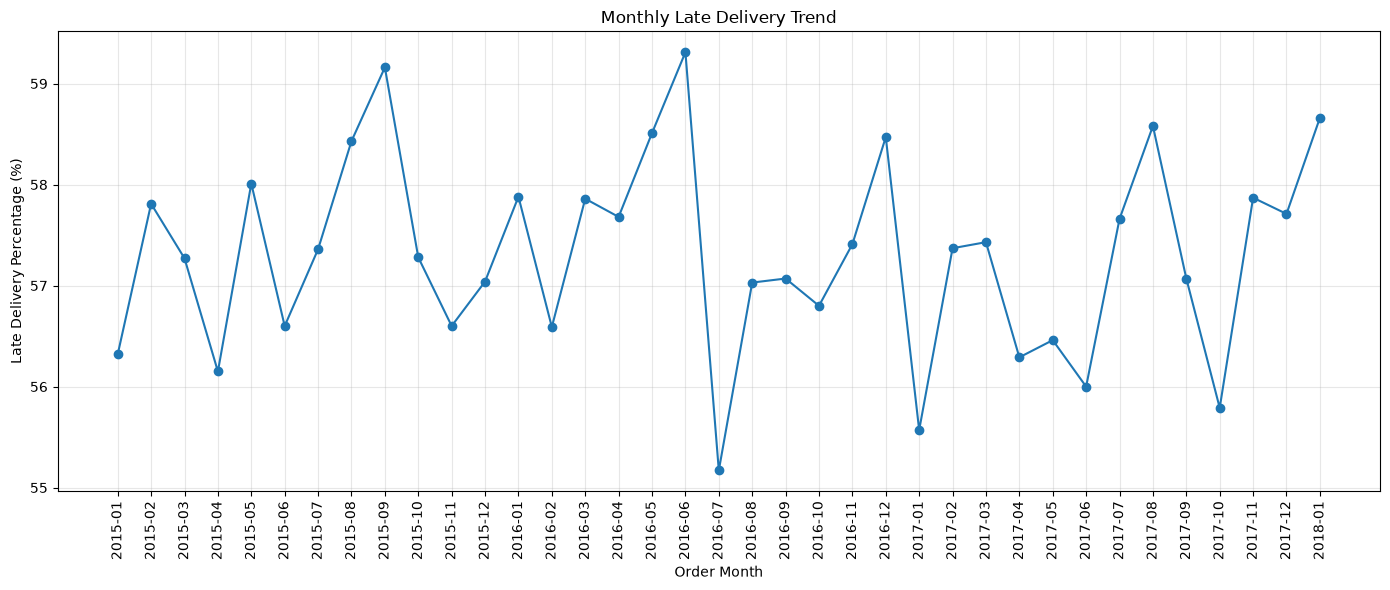

In [14]:
# monthly trend visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Order_Month"],
    monthly_analysis["Late_Delivery_Percentage"],
    marker="o"
)

plt.xlabel("Order Month")
plt.ylabel("Late Delivery Percentage (%)")

plt.title("Monthly Late Delivery Trend")

plt.xticks(rotation=90)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_delivery_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
query = """
SELECT
    [Department Name],

    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Benefit per order] < 0
            THEN 1
            ELSE 0
        END
    ) AS Negative_Profit_Shipments,

    ROUND(
        AVG([Benefit per order]), 2
    ) AS Average_Profit,

    ROUND(
        SUM(
            CASE
                WHEN [Benefit per order] < 0
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Loss_Percentage,

    ROUND(
        SUM([Benefit per order]), 2
    ) AS Total_Profit

FROM supply_chain

GROUP BY [Department Name]

ORDER BY Loss_Percentage DESC;
"""

department_profit = pd.read_sql_query(query, connection)

display(department_profit)

,Department Name,Total_Shipments,Negative_Profit_Shipments,Average_Profit,Loss_Percentage,Total_Profit
0,Health and Beauty,346,81,26.82,23.41,9281.12
1,Pet Shop,472,97,7.43,20.55,3505.18
2,Discs Shop,1943,379,12.43,19.51,24144.80
3,Book Shop,391,75,2.19,19.18,854.44
4,Golf,31768,6020,14.99,18.95,476328.82
5,Apparel,46884,8771,18.03,18.71,845530.37
6,Fan Shop,64033,11963,27.48,18.68,1759600.96
7,Footwear,13891,2593,28.00,18.67,388979.27
8,Outdoors,9267,1655,15.25,17.86,141336.69
9,Fitness,2374,417,19.07,17.57,45270.16


In [16]:
# category-wise profitability analysis

query = """
SELECT
    [Category Name],

    COUNT(*) AS Total_Records,

    SUM(
        CASE
            WHEN [Benefit per order] < 0
            THEN 1
            ELSE 0
        END
    ) AS Negative_Profit_Records,

    ROUND(
        AVG([Benefit per order]), 2
    ) AS Average_Profit,

    ROUND(
        SUM(
            CASE
                WHEN [Benefit per order] < 0
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Loss_Percentage,

    ROUND(
        SUM([Benefit per order]), 2
    ) AS Total_Profit

FROM supply_chain

GROUP BY [Category Name]

HAVING COUNT(*) >= 500

ORDER BY Loss_Percentage DESC;
"""

category_profit = pd.read_sql_query(query, connection)

display(category_profit)

,Category Name,Total_Records,Negative_Profit_Records,Average_Profit,Loss_Percentage,Total_Profit
0,Video Games,804,175,3.14,21.77,2521.35
1,Golf Shoes,502,109,23.11,21.71,11603.53
2,Shop By Sport,10515,2061,11.90,19.60,125077.03
3,Camping & Hiking,13157,2486,31.15,18.89,409895.62
4,Girls' Apparel,1137,214,14.88,18.82,16916.26
5,Water Sports,14880,2799,20.76,18.81,308981.34
6,Indoor/Outdoor Games,18470,3471,16.37,18.79,302403.77
7,Men's Footwear,21263,3993,13.95,18.78,296711.09
8,Cardio Equipment,11948,2237,30.38,18.72,362984.70
9,Cleats,23514,4389,20.18,18.67,474629.51


In [17]:
# discount vs profitability analysis

query = """
SELECT
    CASE
        WHEN [Order Item Discount Rate] <= 0.10
            THEN '0-10%'
        WHEN [Order Item Discount Rate] <= 0.20
            THEN '10-20%'
        WHEN [Order Item Discount Rate] <= 0.30
            THEN '20-30%'
        ELSE 'Above 30%'
    END AS Discount_Range,

    COUNT(*) AS Total_Records,

    SUM(
        CASE
            WHEN [Benefit per order] < 0
            THEN 1
            ELSE 0
        END
    ) AS Negative_Profit_Records,

    ROUND(
        AVG([Benefit per order]), 2
    ) AS Average_Profit,

    ROUND(
        SUM(
            CASE
                WHEN [Benefit per order] < 0
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Loss_Percentage

FROM supply_chain

GROUP BY Discount_Range

ORDER BY
    CASE Discount_Range
        WHEN '0-10%' THEN 1
        WHEN '10-20%' THEN 2
        WHEN '20-30%' THEN 3
        ELSE 4
    END;
"""

discount_profit = pd.read_sql_query(query, connection)

display(discount_profit)

,Discount_Range,Total_Records,Negative_Profit_Records,Average_Profit,Loss_Percentage
0,0-10%,86442,16041,23.75,18.56
1,10-20%,67121,12640,20.72,18.83
2,20-30%,19202,3614,18.88,18.82


In [18]:
# shipping mode vs region risk analysis

query = """
SELECT
    [Order Region],
    [Shipping Mode],

    COUNT(*) AS Total_Shipments,

    SUM(
        CASE
            WHEN [Delivery Status] = 'Late delivery'
            THEN 1
            ELSE 0
        END
    ) AS Late_Shipments,

    ROUND(
        SUM(
            CASE
                WHEN [Delivery Status] = 'Late delivery'
                THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS Late_Delivery_Percentage

FROM supply_chain

GROUP BY
    [Order Region],
    [Shipping Mode]

HAVING COUNT(*) >= 500

ORDER BY Late_Delivery_Percentage DESC;
"""

region_shipping_analysis = pd.read_sql_query(
    query,
    connection
)

display(region_shipping_analysis)

,Order Region,Shipping Mode,Total_Shipments,Late_Shipments,Late_Delivery_Percentage
0,Caribbean,First Class,1132,1132,100.00
1,Central America,First Class,4185,4185,100.00
2,East of USA,First Class,1050,1050,100.00
3,Eastern Asia,First Class,989,989,100.00
4,Eastern Europe,First Class,632,632,100.00
...,...,...,...,...,...
57,West Africa,Standard Class,2188,851,38.89
58,Southern Europe,Standard Class,5403,2071,38.33
59,North Africa,Standard Class,1839,699,38.01
60,Caribbean,Standard Class,4843,1782,36.80


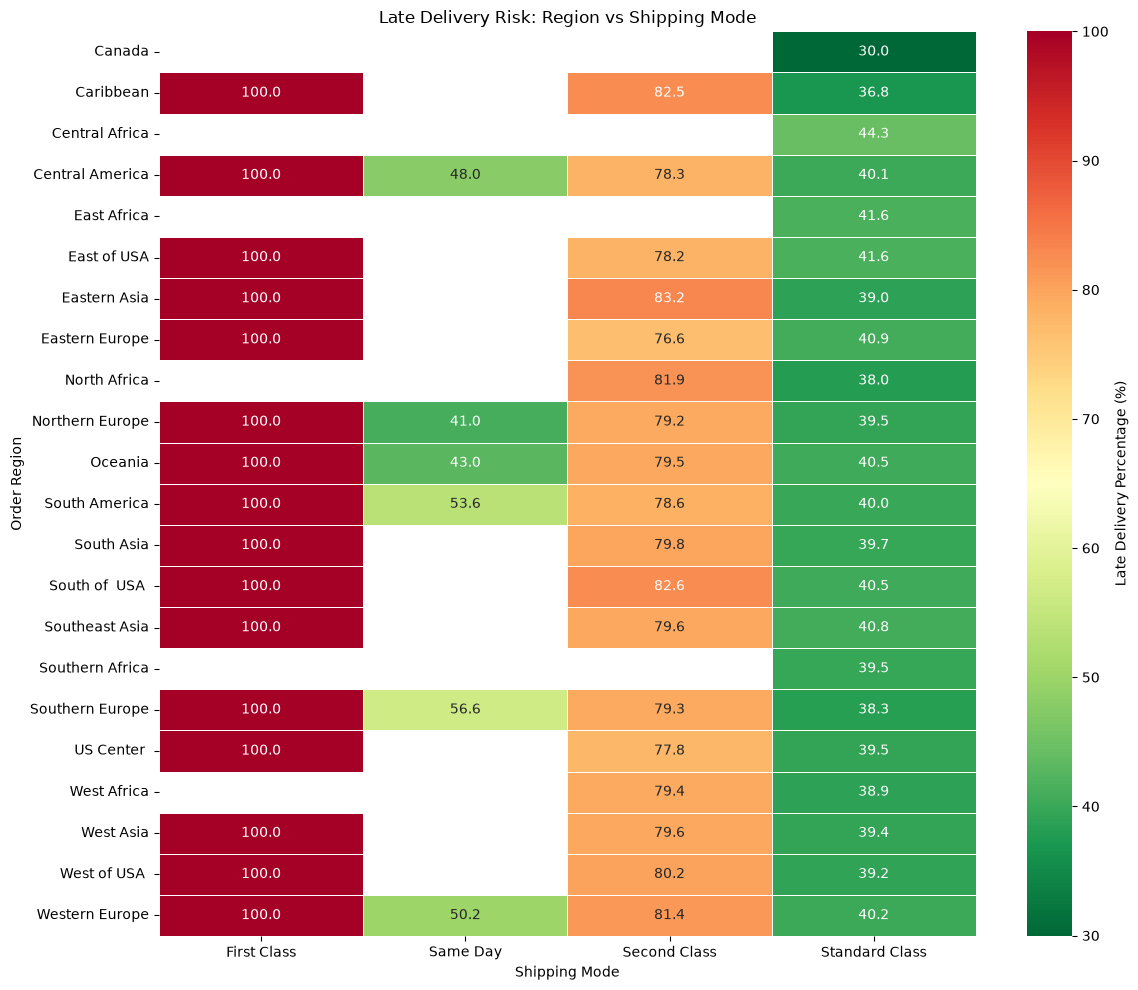

In [19]:
# Region vs Shipping Mode Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Convert SQL result into pivot table
heatmap_data = region_shipping_analysis.pivot(
    index="Order Region",
    columns="Shipping Mode",
    values="Late_Delivery_Percentage"
)

# Create heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={
        "label": "Late Delivery Percentage (%)"
    }
)

plt.title(
    "Late Delivery Risk: Region vs Shipping Mode"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Order Region")

plt.tight_layout()

plt.savefig(
    "../reports/figures/region_shipping_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()